# A/B Test: Moving the First Gate in *Cookie Cats* from Level 30 to Level 40

**Context.** *Cookie Cats* is a mobile puzzle game. At certain levels players hit a **gate**: they must wait or pay to continue.
The team tested moving the first gate from **level 30 (control, `gate_30`)** to **level 40 (treatment, `gate_40`)** on 90,189 new players.

**Decision to make:** should we ship `gate_40`?

**Metrics (decided before looking at results)**
- **Primary:** 7-day retention - the best signal of long-term value.
- **Secondary:** 1-day retention.
- **Engagement:** game rounds played in the first 14 days.

**Plan:** sanity checks (data quality, sample ratio mismatch) -> power -> frequentist test -> bootstrap -> Bayesian view -> decision.

In [1]:
import sys; sys.path.append("..")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from src.abtest import (srm_check, two_proportion_ztest, bootstrap_diff, bayesian_proportions,
                        required_n_per_group, minimum_detectable_effect, peeking_false_positive_rate)

plt.style.use("seaborn-v0_8-whitegrid")
FIG = "../reports/figures/"
df = pd.read_csv("../data/cookie_cats.csv")
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. Data quality checks

In [2]:
print("rows:", len(df), "| unique players:", df["userid"].nunique(), "| missing values:", int(df.isna().sum().sum()))
df.groupby("version").agg(players=("userid", "size"),
                          retention_1=("retention_1", "mean"),
                          retention_7=("retention_7", "mean"),
                          median_rounds=("sum_gamerounds", "median"),
                          max_rounds=("sum_gamerounds", "max")).round(4)

rows: 90189 | unique players: 90189 | missing values: 0


,players,retention_1,retention_7,median_rounds,max_rounds
version,,,,,
gate_30,44700,0.4482,0.1902,17.0,49854
gate_40,45489,0.4423,0.1820,16.0,2640


One player in `gate_30` played **49,854 rounds** in 14 days (~2.5 rounds per minute, nonstop) - almost certainly a bot or a logging error.
It does not affect retention (a 0/1 metric), but it would distort any **mean** of game rounds, so engagement is analysed with medians, ranks and a capped mean.

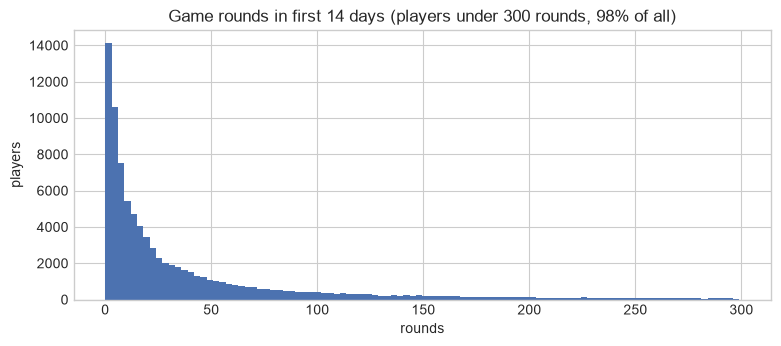

players with 0 rounds: 4.4%


In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(df.loc[df.sum_gamerounds < 300, "sum_gamerounds"], bins=100, color="#4C72B0")
ax.set(title="Game rounds in first 14 days (players under 300 rounds, 98% of all)", xlabel="rounds", ylabel="players")
plt.savefig(FIG + "rounds_distribution.png", dpi=150, bbox_inches="tight"); plt.show()
print("players with 0 rounds:", f"{(df.sum_gamerounds == 0).mean():.1%}")

### Sample Ratio Mismatch (SRM)
If the split was designed as 50/50, a big imbalance means something went wrong in assignment or logging - and the result may be biased.

In [4]:
n30, n40 = (df.version == "gate_30").sum(), (df.version == "gate_40").sum()
srm = srm_check(n30, n40)
srm

{'n_a': np.int64(44700),
 'n_b': np.int64(45489),
 'share_a': np.float64(0.49562585237667567),
 'chi2': 6.9024049496058275,
 'p_value': 0.008607987810836243}

**Finding: there is a statistically significant SRM** (p ≈ 0.009). The split is 49.6% / 50.4% instead of 50/50.

- The gap is small (≈ 400 players), and we do not know if 50/50 was the intended design.
- A real SRM can come from, for example, players in one group crashing before being logged.
- **Action:** report the results, but flag the SRM to the engineering team and **treat the conclusion with extra caution**. In a real company I would investigate before shipping.

## 2. Power: could this test detect a meaningful effect?

In [5]:
n = min(n30, n40)
for metric in ["retention_1", "retention_7"]:
    base = df.loc[df.version == "gate_30", metric].mean()
    mde = minimum_detectable_effect(base, n)
    print(f"{metric}: baseline {base:.2%}, minimum detectable effect with {n:,} per group = {mde:.2%} (absolute)")

retention_1: baseline 44.82%, minimum detectable effect with 44,700 per group = 0.93% (absolute)
retention_7: baseline 19.02%, minimum detectable effect with 44,700 per group = 0.74% (absolute)


With ~45k players per group the test can detect changes of about **0.9 pp** in 1-day retention and **0.7 pp** in 7-day retention (80% power, 5% significance).

## 3. Frequentist test

In [6]:
results = {}
for metric in ["retention_1", "retention_7"]:
    a = df.loc[df.version == "gate_30", metric]
    b = df.loc[df.version == "gate_40", metric]
    t = two_proportion_ztest(a.sum(), len(a), b.sum(), len(b))
    results[metric] = t
    print(f"{metric}: gate_30 {t.rate_a:.2%} -> gate_40 {t.rate_b:.2%} | diff {t.diff:+.2%} "
          f"(95% CI {t.ci_low:+.2%} to {t.ci_high:+.2%}) | relative {t.relative_lift:+.1%} | p = {t.p_value:.4f}")

retention_1: gate_30 44.82% -> gate_40 44.23% | diff -0.59% (95% CI -1.24% to +0.06%) | relative -1.3% | p = 0.0744
retention_7: gate_30 19.02% -> gate_40 18.20% | diff -0.82% (95% CI -1.33% to -0.31%) | relative -4.3% | p = 0.0016


- **7-day retention drops by 0.82 pp (-4.3% relative), p ≈ 0.002.** Significant.
- **1-day retention drops by 0.59 pp, p ≈ 0.07.** Not significant at 5%, but points the same way.

## 4. Bootstrap (no distribution assumptions)

retention_1: P(gate_40 worse) = 96.8%, 95% interval -1.23% to +0.05%


retention_7: P(gate_40 worse) = 99.9%, 95% interval -1.33% to -0.32%


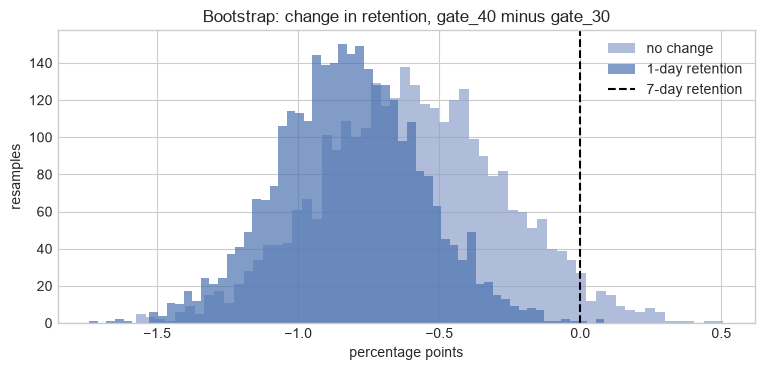

In [7]:
boot = {}
for metric in ["retention_1", "retention_7"]:
    a = df.loc[df.version == "gate_30", metric].values.astype(float)
    b = df.loc[df.version == "gate_40", metric].values.astype(float)
    boot[metric] = bootstrap_diff(a, b, n_boot=3000, seed=42)
    print(f"{metric}: P(gate_40 worse) = {(boot[metric] < 0).mean():.1%}, 95% interval "
          f"{np.quantile(boot[metric], 0.025):+.2%} to {np.quantile(boot[metric], 0.975):+.2%}")

fig, ax = plt.subplots(figsize=(9, 3.8))
for metric, color in [("retention_1", "#8DA0CB"), ("retention_7", "#4C72B0")]:
    ax.hist(boot[metric] * 100, bins=60, alpha=0.7, color=color, label=metric.replace("_", " ") + "-day")
ax.axvline(0, color="black", ls="--")
ax.set(title="Bootstrap: change in retention, gate_40 minus gate_30", xlabel="percentage points", ylabel="resamples")
ax.legend(["no change", "1-day retention", "7-day retention"])
plt.savefig(FIG + "bootstrap_retention.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Bayesian view: how sure are we, and what does a wrong decision cost?

In [8]:
bayes = {}
for metric in ["retention_1", "retention_7"]:
    a = df.loc[df.version == "gate_30", metric]
    b = df.loc[df.version == "gate_40", metric]
    bayes[metric] = bayesian_proportions(a.sum(), len(a), b.sum(), len(b))
pd.DataFrame(bayes).T

,prob_a_better,expected_loss_choose_a,expected_loss_choose_b,diff_ci95
retention_1,0.962945,0.000049,0.005965,"[-0.012375889472726286, 0.0005766731057186529]"
retention_7,0.99916,0.000001,0.008207,"[-0.013288497795718376, -0.003112551845360416]"


- There is a **99.9% probability that gate_30 has better 7-day retention**.
- Expected loss if we ship gate_40: about **0.8 pp of 7-day retention**; if we keep gate_30: essentially **0**.

## 6. Engagement: game rounds

In [9]:
a = df.loc[df.version == "gate_30", "sum_gamerounds"]
b = df.loc[df.version == "gate_40", "sum_gamerounds"]
cap = df["sum_gamerounds"].quantile(0.999)
mw = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"median rounds: gate_30 {a.median():.0f}, gate_40 {b.median():.0f}")
print(f"mean rounds (capped at 99.9th pct = {cap:.0f}): gate_30 {a.clip(upper=cap).mean():.1f}, gate_40 {b.clip(upper=cap).mean():.1f}")
print(f"Mann-Whitney U p-value: {mw.pvalue:.3f}")

median rounds: gate_30 17, gate_40 16
mean rounds (capped at 99.9th pct = 1074): gate_30 51.0, gate_40 50.9
Mann-Whitney U p-value: 0.050


Engagement is practically the same: the capped mean is 51.0 vs 50.9 rounds and the median 17 vs 16. The rank test is borderline (p = 0.05) and, if anything, slightly favours gate_30. So there is **no engagement gain** that could offset the retention loss.

> I did **not** split retention results by "number of rounds played", because rounds are affected by the treatment itself. Segmenting by a post-treatment variable creates biased comparisons.

## 7. Why we wait for the planned sample: the cost of peeking
A common mistake is checking the p-value every day and stopping as soon as it is below 0.05.
This simulation runs **A/A tests** (no real difference) with the same baseline as our primary metric.

In [10]:
peek = peeking_false_positive_rate(p=0.19, n_per_group=20_000, looks=14, sims=1000, seed=1)
peek

{'looks': 14,
 'false_positive_single_look': 0.044,
 'false_positive_with_peeking': 0.221}

Checking 14 times (e.g. daily for two weeks) raises the false-positive rate far above the promised 5%. Fixed-horizon tests must be read **once**, or a sequential method must be used.

## 8. Results summary

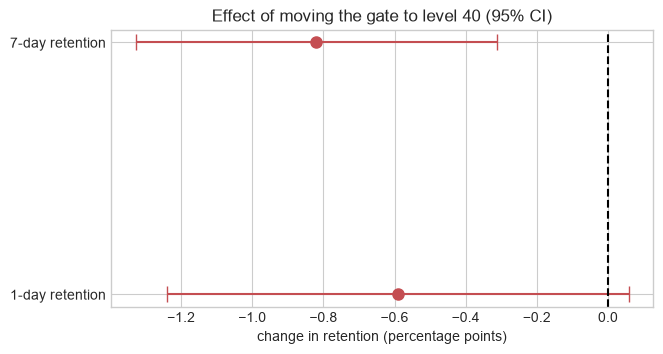

{'retention_1': {'gate_30': 0.4482,
  'gate_40': 0.4423,
  'diff_pp': -0.59,
  'ci95_pp': [-1.24, 0.06],
  'p_value': 0.0744,
  'prob_gate_30_better': 0.9629},
 'retention_7': {'gate_30': 0.1902,
  'gate_40': 0.182,
  'diff_pp': -0.82,
  'ci95_pp': [-1.33, -0.31],
  'p_value': 0.0016,
  'prob_gate_30_better': 0.9992}}

In [11]:
summary = {
    "players": int(len(df)),
    "srm": {"share_gate_30": round(float(srm["share_a"]), 4), "p_value": round(srm["p_value"], 4)},
    "retention": {m: {"gate_30": round(float(t.rate_a), 4), "gate_40": round(float(t.rate_b), 4),
                      "diff_pp": round(float(100 * t.diff), 2),
                      "ci95_pp": [round(float(100 * t.ci_low), 2), round(float(100 * t.ci_high), 2)],
                      "p_value": round(t.p_value, 4),
                      "prob_gate_30_better": round(bayes[m]["prob_a_better"], 4)}
                  for m, t in results.items()},
    "mde_pp": {m: round(100 * minimum_detectable_effect(df.loc[df.version == "gate_30", m].mean(), n), 2)
               for m in ["retention_1", "retention_7"]},
    "peeking_simulation": peek,
}
json.dump(summary, open("../reports/results.json", "w"), indent=2)

fig, ax = plt.subplots(figsize=(7, 3.6))
labels, diffs, lo, hi = [], [], [], []
for m, t in results.items():
    labels.append(m.replace("retention_", "") + "-day retention")
    diffs.append(100 * t.diff); lo.append(100 * (t.diff - t.ci_low)); hi.append(100 * (t.ci_high - t.diff))
ax.errorbar(diffs, labels, xerr=[lo, hi], fmt="o", color="#C44E52", capsize=6, ms=8)
ax.axvline(0, color="black", ls="--")
ax.set(title="Effect of moving the gate to level 40 (95% CI)", xlabel="change in retention (percentage points)")
plt.savefig(FIG + "effect_summary.png", dpi=150, bbox_inches="tight"); plt.show()
summary["retention"]

## 9. Recommendation

**Do not ship `gate_40`. Keep the first gate at level 30.**

- 7-day retention falls from 19.0% to 18.2% (-0.82 pp, p ≈ 0.002; 99.9% Bayesian probability that gate_30 is better).
- 1-day retention and engagement show no gain that could offset this.
- A likely explanation: an earlier gate gives players a break, which keeps the game enjoyable for longer (hedonic adaptation).

**Caveats and follow-ups**
1. Investigate the sample ratio mismatch before treating the result as final.
2. Retention is a proxy; the business also cares about revenue. A follow-up test should track purchases at the gate.
3. Test an even earlier gate (e.g. level 20) to see whether the effect continues.